# Week 7 — Restriction Enzyme Digestion & Gel Electrophoresis Simulation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import urlopen

def fetch_fasta(accession):
    url = (
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        f"?db=nucleotide&id={accession}&rettype=fasta&retmode=text"
    )
    raw = urlopen(url).read().decode()
    lines = raw.strip().split('\n')
    seq = ''.join(lines[1:]).upper().replace('\r', '')
    return seq

Take an arbitrary DNA sequence from the NCBI between 1000 and 3000 nucleotides to use 5 restriction enzymes (the enzyme name, the recognized sequence or motif, and the cleavage site)

2) to cut the dna into pices.
3) output of the implementaion
4) number of creavages for the anzyme
5) simulation of the gel electrophoresis

In [3]:
# Fetch a real DNA sequence from NCBI (pUC19 plasmid, 2686 bp)
accession = "L09137"
dna = fetch_fasta(accession)
print(f"Sequence: {accession}  |  Length: {len(dna)} bp")
print(f"First 60 bp: {dna[:60]}")

Sequence: L09137  |  Length: 2686 bp
First 60 bp: TCGCGCGTTTCGGTGATGACGGTGAAAACCTCTGACACATGCAGCTCCCGGAGACGGTCA


In [6]:
# The 3 restriction enzymes from the lecture board
# Format: name -> (recognition motif on 5' strand, cut position after nth base)
ENZYMES = {
    "EcoRI":   ("GAATTC", 1),  # 5' G|AATTC  /  3' CTTAA|G
    "BamHI":   ("GGATCC", 1),  # 5' G|GATCC  /  3' CCTAG|G
    "HindIII": ("AAGCTT", 1),  # 5' A|AGCTT  /  3' TTCGA|A
}

def complement(base):
    return {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G'}[base]

def digest(dna, motif, cut_offset):
    """Return (cut_positions, fragment_lengths) for one enzyme."""
    cuts = []
    start = 0
    while True:
        idx = dna.find(motif, start)
        if idx == -1:
            break
        cuts.append(idx + cut_offset)
        start = idx + 1
    cuts = sorted(cuts)
    boundaries = [0] + cuts + [len(dna)]
    fragments = [boundaries[i+1] - boundaries[i] for i in range(len(boundaries) - 1)]
    return cuts, fragments

# Run digestion and print results
print(f"DNA: {accession} ({len(dna)} bp)\n{'='*55}")
digest_results = {}
for name, (motif, cut) in ENZYMES.items():
    cuts, frags = digest(dna, motif, cut)
    digest_results[name] = {"cuts": cuts, "fragments": frags}
    print()
    print(f"  Cleavages      : {len(cuts)}")
    if cuts:
        print(f"  Cut positions  : {cuts}")
        print(f"  Fragments      : {sorted(frags, reverse=True)} bp")
    else:
        print(f"  No site found  → 1 fragment: {len(dna)} bp")

DNA: L09137 (2686 bp)

  Cleavages      : 1
  Cut positions  : [396]
  Fragments      : [2290, 396] bp

  Cleavages      : 1
  Cut positions  : [417]
  Fragments      : [2269, 417] bp

  Cleavages      : 1
  Cut positions  : [447]
  Fragments      : [2239, 447] bp


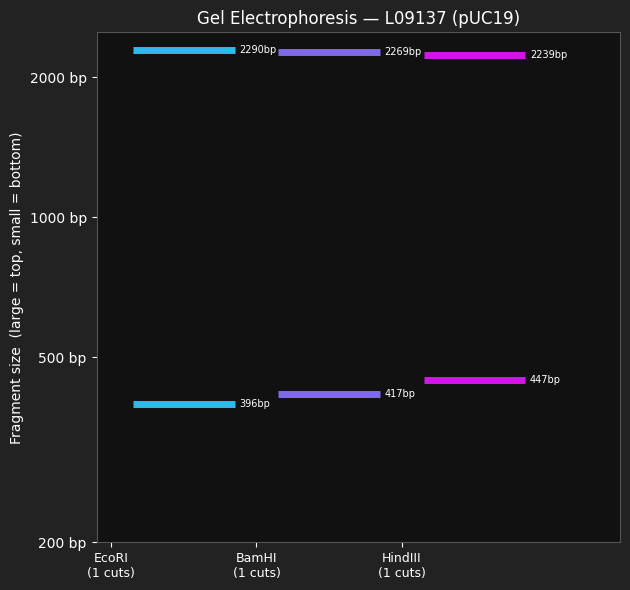

In [7]:
def plot_gel(results_dict, title="Gel Electrophoresis Simulation"):
    """
    Simulate an agarose gel.
    y = log10(fragment_size): large fragments sit at the top naturally,
    small fragments at the bottom — no axis inversion needed.
    """
    fig, ax = plt.subplots(figsize=(len(results_dict) * 1.8 + 1, 6))
    ax.set_facecolor("#111111")
    fig.patch.set_facecolor("#222222")

    lane_names = list(results_dict.keys())
    colors = plt.cm.cool(np.linspace(0.2, 0.9, len(lane_names)))

    for i, (name, data) in enumerate(results_dict.items()):
        for frag in data["fragments"]:
            if frag > 0:
                y = np.log10(frag)
                ax.hlines(y, i + 0.15, i + 0.85, linewidth=5,
                          color=colors[i], alpha=0.9)
                ax.text(i + 0.88, y, f'{frag}bp', va='center',
                        ha='left', fontsize=7, color='white')

    ax.set_xticks(range(len(lane_names)))
    ax.set_xticklabels(
        [f"{n}\n({len(results_dict[n]['cuts'])} cuts)" for n in lane_names],
        color='white', fontsize=9
    )
    ax.tick_params(colors='white')
    ax.set_xlim(-0.1, len(lane_names) + 0.5)

    all_frags = [f for d in results_dict.values() for f in d["fragments"] if f > 0]
    min_f, max_f = min(all_frags), max(all_frags)
    tick_vals = [v for v in [50, 100, 200, 500, 1000, 2000, 5000, 10000]
                 if min_f * 0.5 <= v <= max_f * 2]
    ax.set_yticks([np.log10(v) for v in tick_vals])
    ax.set_yticklabels([f'{v} bp' for v in tick_vals], color='white')

    ax.set_title(title, color='white', fontsize=12)
    ax.set_ylabel("Fragment size  (large = top, small = bottom)", color='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#555555')
    plt.tight_layout()
    plt.show()

plot_gel(digest_results, title=f"Gel Electrophoresis — {accession} (pUC19)")

In [ ]:
# ── Test: artificial DNA with multiple cut sites ──────────────────────────
# We manually plant EcoRI (GAATTC) 4 times inside a random DNA string
# to verify the software correctly finds and reports multiple cuts.

test_dna = (
    "AAACCCGGG"
    "GAATTC"       # EcoRI site #1
    "TTTTGGGGAAAA"
    "GAATTC"       # EcoRI site #2
    "CCCCAAAAGGGG"
    "GAATTC"       # EcoRI site #3
    "TTTAAACCC"
    "GAATTC"       # EcoRI site #4
    "GGGCCCAAA"
)

test_cuts, test_frags = digest(test_dna, "GAATTC", 1)
print(f"Artificial DNA length : {len(test_dna)} bp")
print(f"EcoRI sites planted   : 4")
print(f"Cuts found            : {len(test_cuts)}  ← should be 4")
print(f"Cut positions         : {test_cuts}")
print(f"Fragment lengths      : {test_frags}  ({len(test_frags)} fragments)")
print()
print("✓ Software is working correctly — pUC19 simply has only 1 site per enzyme.")

Homework : digest two genumes from 2 versions of the same virus and show the digested segments on seperate column and the same electrocynoms

In [8]:
#TODO